# Mapping where Hurricane Harvey flooding was worst

**Idea:** ask Qwen3-VL what percent of each aerial image is water, once for the 2016
"before" image and once for the image taken just after Hurricane Harvey in 2017.
The increase is new floodwater. Colour each ~530 m image footprint by that increase
to see which neighbourhoods flooded worst, then check Qwen against hand labels.

Settings (model server, data folder, prompt) live in `config.py`.

In [1]:
import pandas as pd

import config
from flood_heatmap import (download_dataset, load_harvey_pairs, score_images, recheck_no_flood,
                           flood_table, flood_map, show_pair)
from labeling import load_labels, compare_with_model

print("Model server:  ", config.VLM_BASE_URL)
print("Dataset folder:", config.DATA_DIR)

Model server:   http://10.42.0.52:8000/v1
Dataset folder: /home/matthew/Documents/dell-datathon/harvey-flood-heatmap/data/Texas_Flood_Student_Data


## 1. Download the dataset

About 1.6 GB the first time; later runs only check for changes.

In [2]:
download_dataset()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1219 files:   0%|          | 0/1219 [00:00<?, ?it/s]

## 2. Load the image pairs

Each row is one 2017 NOAA after-image with the 2016 USDA image of the same footprint.

In [3]:
pairs = load_harvey_pairs()
pairs["locality"].value_counts()

locality
West Houston / Addicks and Barker    250
Richmond / Rosenberg / Brazos        165
Forest Cove / Kingwood                85
Bevil Oaks / Pine Island Bayou        25
Simonton / Brazos                     25
Bear Creek / west Houston             10
Kingwood / northeast Houston           8
Eldridge / northwest Houston           7
Name: count, dtype: int64

## 3. Score every image with Qwen

**Pass 1:** one call per image asking what percent is water (1,150 calls, about 8 minutes
on the GB10), saved to `results/water_scores.csv`.

**Pass 2:** Qwen sometimes reads muddy water filling the whole frame as bare soil. For every
tile where pass 1 found no new flood, ask a yes/no floodwater question about the after-image;
on "yes", ask for the water percent again with a note that floodwater is present. Saved to
`results/recheck_scores.csv`.

Both passes save as they go, so a rerun skips work already done. The prompts are in
`config.py`. To try a different prompt, pass `out_csv=` and `prompt=` to `score_images` so
the main scores stay intact.

In [4]:
scores = score_images(pairs)
rechecks = recheck_no_flood(flood_table(pairs, scores))
table = flood_table(pairs, scores, rechecks)
print(f"{table['rechecked'].sum()} tiles flagged by the recheck and re-estimated")

1150 images already scored, 0 to go
90 tiles already rechecked, 0 to go
39 tiles flagged by the recheck and re-estimated


## 4. Which tiles flooded worst?

In [5]:
columns = ["after_id", "locality", "before_water_pct", "after_water_pct", "new_flood_pct"]
table.sort_values("new_flood_pct", ascending=False)[columns].head(15)

,after_id,locality,before_water_pct,after_water_pct,new_flood_pct
59,TXH_15325_27128_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,99,99
414,TXH_15351_27095_after_20170830_NOAA,West Houston / Addicks and Barker,0,99,99
55,TXH_15325_27124_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,98,98
81,TXH_15330_27126_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,98,98
431,TXH_15352_27094_after_20170830_NOAA,West Houston / Addicks and Barker,0,98,98
70,TXH_15327_27126_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,98,98
69,TXH_15327_27125_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,95,95
56,TXH_15325_27125_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,95,95
75,TXH_15328_27126_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,95,95
76,TXH_15328_27127_after_20170831_NOAA,Richmond / Rosenberg / Brazos,0,95,95


In [6]:
table.groupby("locality")["new_flood_pct"].agg(["count", "mean", "median"]).round(1).sort_values("mean", ascending=False)

,count,mean,median
locality,,,
Richmond / Rosenberg / Brazos,165,63.1,75.0
Eldridge / northwest Houston,7,62.1,65.0
Bear Creek / west Houston,10,56.3,70.0
Kingwood / northeast Houston,8,55.0,62.5
Bevil Oaks / Pine Island Bayou,25,52.2,65.0
Simonton / Brazos,25,48.0,55.0
West Houston / Addicks and Barker,250,46.2,45.0
Forest Cove / Kingwood,85,30.4,25.0


## 5. Map

Hover over a tile for its numbers. Use the layer control (top right) to switch to
satellite or hide the flood layer. Also saved to `results/flood_map.html`.

In [7]:
fmap = flood_map(table)
fmap.save(config.MAP_HTML)
fmap

## 6. Check a tile by eye

These are model estimates, not measurements. Swap in any `after_id` from a map tooltip.

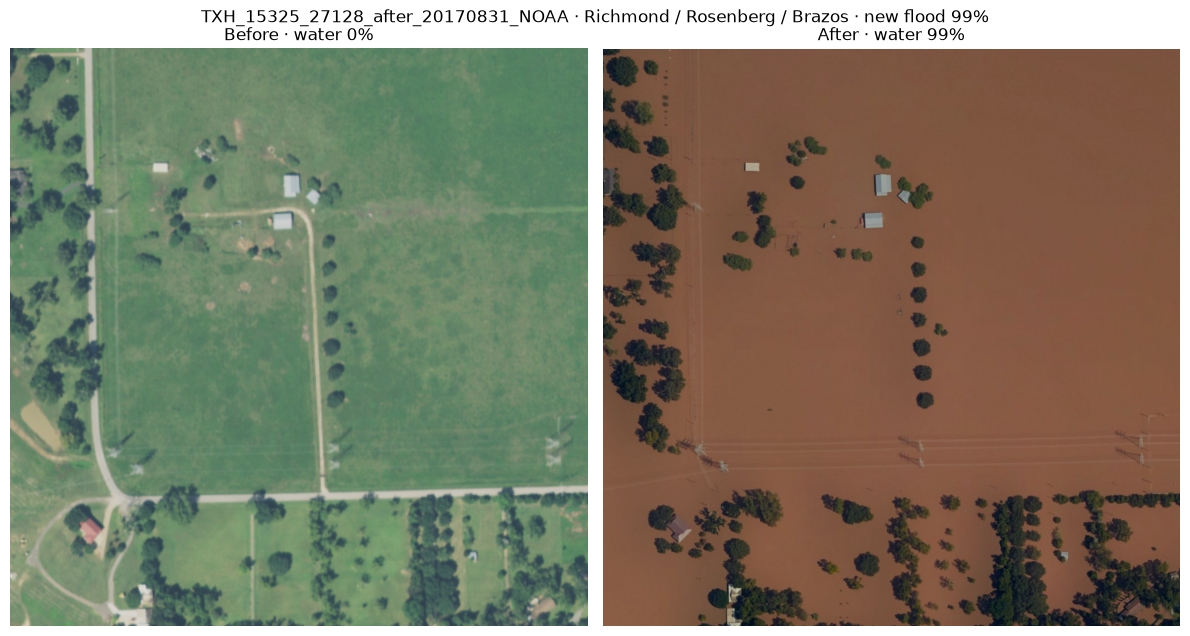

In [8]:
show_pair(table.sort_values("new_flood_pct", ascending=False).iloc[0])

## 7. Compare with hand labels

Reads every `labels/set_*/labels.csv` and keeps the rows that have been filled in.
Sets A and D were used to choose prompts; sets B and C are held out for the reported
accuracy. `experiments/prompt_experiments.py` reruns the full prompt comparison.

In [9]:
labels = load_labels()
first_pass = flood_table(pairs, scores)
pd.DataFrame({
    (name, version): compare_with_model(labels[labels["label_set"].isin(sets)], t)[1]
    for name, sets in [("Development (A + D)", ["set_A", "set_D"]), ("Held out (B + C)", ["set_B", "set_C"])]
    for version, t in [("pass 1 only", first_pass), ("with recheck", table)]
})

Development (A + D)                   \
                                                 pass 1 only     with recheck   
tiles labelled                                            35               35   
flooded/dry agreement                        68% of 31 tiles  84% of 31 tiles   
mean absolute error (points)                            17.5             11.5   
mean error (points, + = Qwen reads high)                -9.8             -0.5   

                                         Held out (B + C)                   
                                              pass 1 only     with recheck  
tiles labelled                                         40               40  
flooded/dry agreement                     83% of 35 tiles  91% of 35 tiles  
mean absolute error (points)                         19.6             19.4  
mean error (points, + = Qwen reads high)             -4.4              3.3

In [10]:
# Biggest disagreements first
both, _ = compare_with_model(labels, table)
both.assign(abs_error=both["error"].abs()).sort_values("abs_error", ascending=False)[
    ["label_set", "label_no", "flood_visible", "new_flood_pct", "model_new_flood_pct", "locality"]].head(10)

,label_set,label_no,flood_visible,new_flood_pct,model_new_flood_pct,locality
25,set_B,26,yes,12.0,75,West Houston / Addicks and Barker
38,set_B,39,yes,68.0,10,Forest Cove / Kingwood
45,set_C,46,yes,24.0,65,Simonton / Brazos
23,set_B,24,yes,100.0,60,West Houston / Addicks and Barker
68,set_D,69,yes,60.0,20,West Houston / Addicks and Barker
21,set_B,22,yes,84.0,45,West Houston / Addicks and Barker
41,set_C,42,yes,88.0,50,West Houston / Addicks and Barker
53,set_C,54,yes,48.0,85,West Houston / Addicks and Barker
17,set_A,18,yes,44.0,75,Richmond / Rosenberg / Brazos
49,set_C,50,yes,80.0,50,West Houston / Addicks and Barker


**Keep in mind:** this is one storm. Addicks and Barker flooded largely from the
reservoir pools behind their dams; Richmond and Kingwood flooded from rivers leaving
their banks. NOAA photographed where the damage was, so the map compares tiles within
the photographed areas only. Grading rules the team has agreed are in `flood_rules.md`.